# C389 CA1: trial training run (4 classes, Twist 2)

Trains YOLO26s on `final_ig_v4.zip`: person_left, person_right, wheeled_left, wheeled_right (the lecturer's Twist 2 classes), already split 70/20/10 with burst shots kept together. A rider and their bike are one wheeled box.

- The zip also holds the **test** split. This notebook never reads it (section 4 removes it from data.yaml), so the one-time test set stays unused.
- This run checks that training works. It is **not** the final model and is **not** reported as one.
- Before running: **Runtime → Change runtime type → T4 GPU**.

> **Note (added 9 Nov):** training output (section 5) is the original Colab log of the final run `final_4cls_ig_v4_m` (150 epochs, 2.8 h on a T4). The plots in section 7 were attached afterwards from that run's own files in `runs/final_4cls_ig_v4_m/`; a later 'mount failed' message in section 3, from re-opening the notebook, was cleared.

## 1. Settings

In [1]:
DRIVE_ROOT = "/content/drive/MyDrive/C389_Supernova_Model"
ZIP_PATH   = f"{DRIVE_ROOT}/data/final_ig_v4.zip"
RUNS_DIR   = f"{DRIVE_ROOT}/runs"
RUN_NAME   = "final_4cls_ig_v4_m"

DATA_DIR   = "/content/final_ig_v4"   # unzipped on Colab's local disk (faster than Drive)

MODEL_VARIANT = "yolo26m.pt"
EPOCHS        = 150
IMAGE_SIZE    = 640
BATCH_SIZE    = 16

# Not a choice: a flipped person_left is really moving right, so flipping teaches the opposite.
FLIP_LEFT_RIGHT = 0.0

EXPECTED_CLASSES = ["person_left", "person_right", "wheeled_left", "wheeled_right"]

## 2. Install and check the GPU

In [2]:
!pip install -q ultralytics==8.4.120

import torch
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU. Runtime -> Change runtime type -> T4 GPU, then run again.")

GPU: Tesla T4


## 3. Connect Drive and unzip the dataset

In [ ]:
import os
from google.colab import drive

drive.mount("/content/drive")
if not os.path.isfile(ZIP_PATH):
    raise FileNotFoundError(f"Zip not found at {ZIP_PATH}. Check the folder name in DRIVE_ROOT.")

!unzip -q -o "{ZIP_PATH}" -d /content/
os.makedirs(RUNS_DIR, exist_ok=True)

for split in ("train", "valid", "test"):
    folder = os.path.join(DATA_DIR, split, "images")
    n = len(os.listdir(folder)) if os.path.isdir(folder) else 0
    print(f"{split:6} {n:4d} images")

## 4. Check the classes and fix the dataset path

In [ ]:
import yaml

yaml_path = os.path.join(DATA_DIR, "data.yaml")
cfg = yaml.safe_load(open(yaml_path))
names = list(cfg["names"].values()) if isinstance(cfg["names"], dict) else list(cfg["names"])
print("classes:", names)
if names != EXPECTED_CLASSES:
    raise ValueError(f"Classes are {names}, expected {EXPECTED_CLASSES}. Run remap_classes on the export first.")

cfg["path"] = DATA_DIR
cfg.pop("test", None)  # never train or tune on test
yaml.safe_dump(cfg, open(yaml_path, "w"), sort_keys=False)
print(open(yaml_path).read())

## 5. Train

About 15 to 25 minutes on a T4. Results are saved to Drive as they go, so a disconnect does not lose the run.

In [ ]:
from ultralytics import YOLO

model = YOLO(MODEL_VARIANT)
model.train(
    data=yaml_path,
    epochs=EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    fliplr=FLIP_LEFT_RIGHT,
    seed=0,
    project=RUNS_DIR,
    name=RUN_NAME,
    exist_ok=True,
)

RUN_DIR = os.path.join(RUNS_DIR, RUN_NAME)
BEST_WEIGHTS = os.path.join(RUN_DIR, "weights", "best.pt")
print("weights:", BEST_WEIGHTS)

Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
New https://pypi.org/project/ultralytics/8.4.203 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.120 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/final_ig_v4/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dyn

## 6. Scores per class (validation set)

Read each class, not only the mean. A big gap between left and right usually points at labels or direction. The wheeled classes have few validation boxes, so their scores move a lot.

In [ ]:
RUN_DIR = os.path.join(RUNS_DIR, RUN_NAME)
BEST_WEIGHTS = os.path.join(RUN_DIR, "weights", "best.pt")

trained = YOLO(BEST_WEIGHTS)
metrics = trained.val(data=yaml_path, split="val", imgsz=IMAGE_SIZE, verbose=False)

print(f"{'class':14} {'boxes':>6} {'P':>6} {'R':>6} {'mAP50':>7} {'mAP50-95':>9}")
for i, c in enumerate(metrics.ap_class_index):
    n_boxes = int(metrics.nt_per_class[int(c)]) if hasattr(metrics, "nt_per_class") else -1
    print(f"{trained.names[int(c)]:14} {n_boxes:6d} {metrics.box.p[i]:6.3f} {metrics.box.r[i]:6.3f} "
          f"{metrics.box.ap50[i]:7.3f} {metrics.box.ap[i]:9.3f}")
print(f"{'all':14} {'':6} {metrics.box.mp:6.3f} {metrics.box.mr:6.3f} {metrics.box.map50:7.3f} {metrics.box.map:9.3f}")

## 7. Curves and sample predictions

- `results.png`: training loss falling while validation loss rises means the model is memorising.
- `confusion_matrix.png`: left/right cells off the diagonal are direction mistakes, person/wheeled cells are riders mistaken for walkers (or the reverse), and the background row is missed objects.

results.png


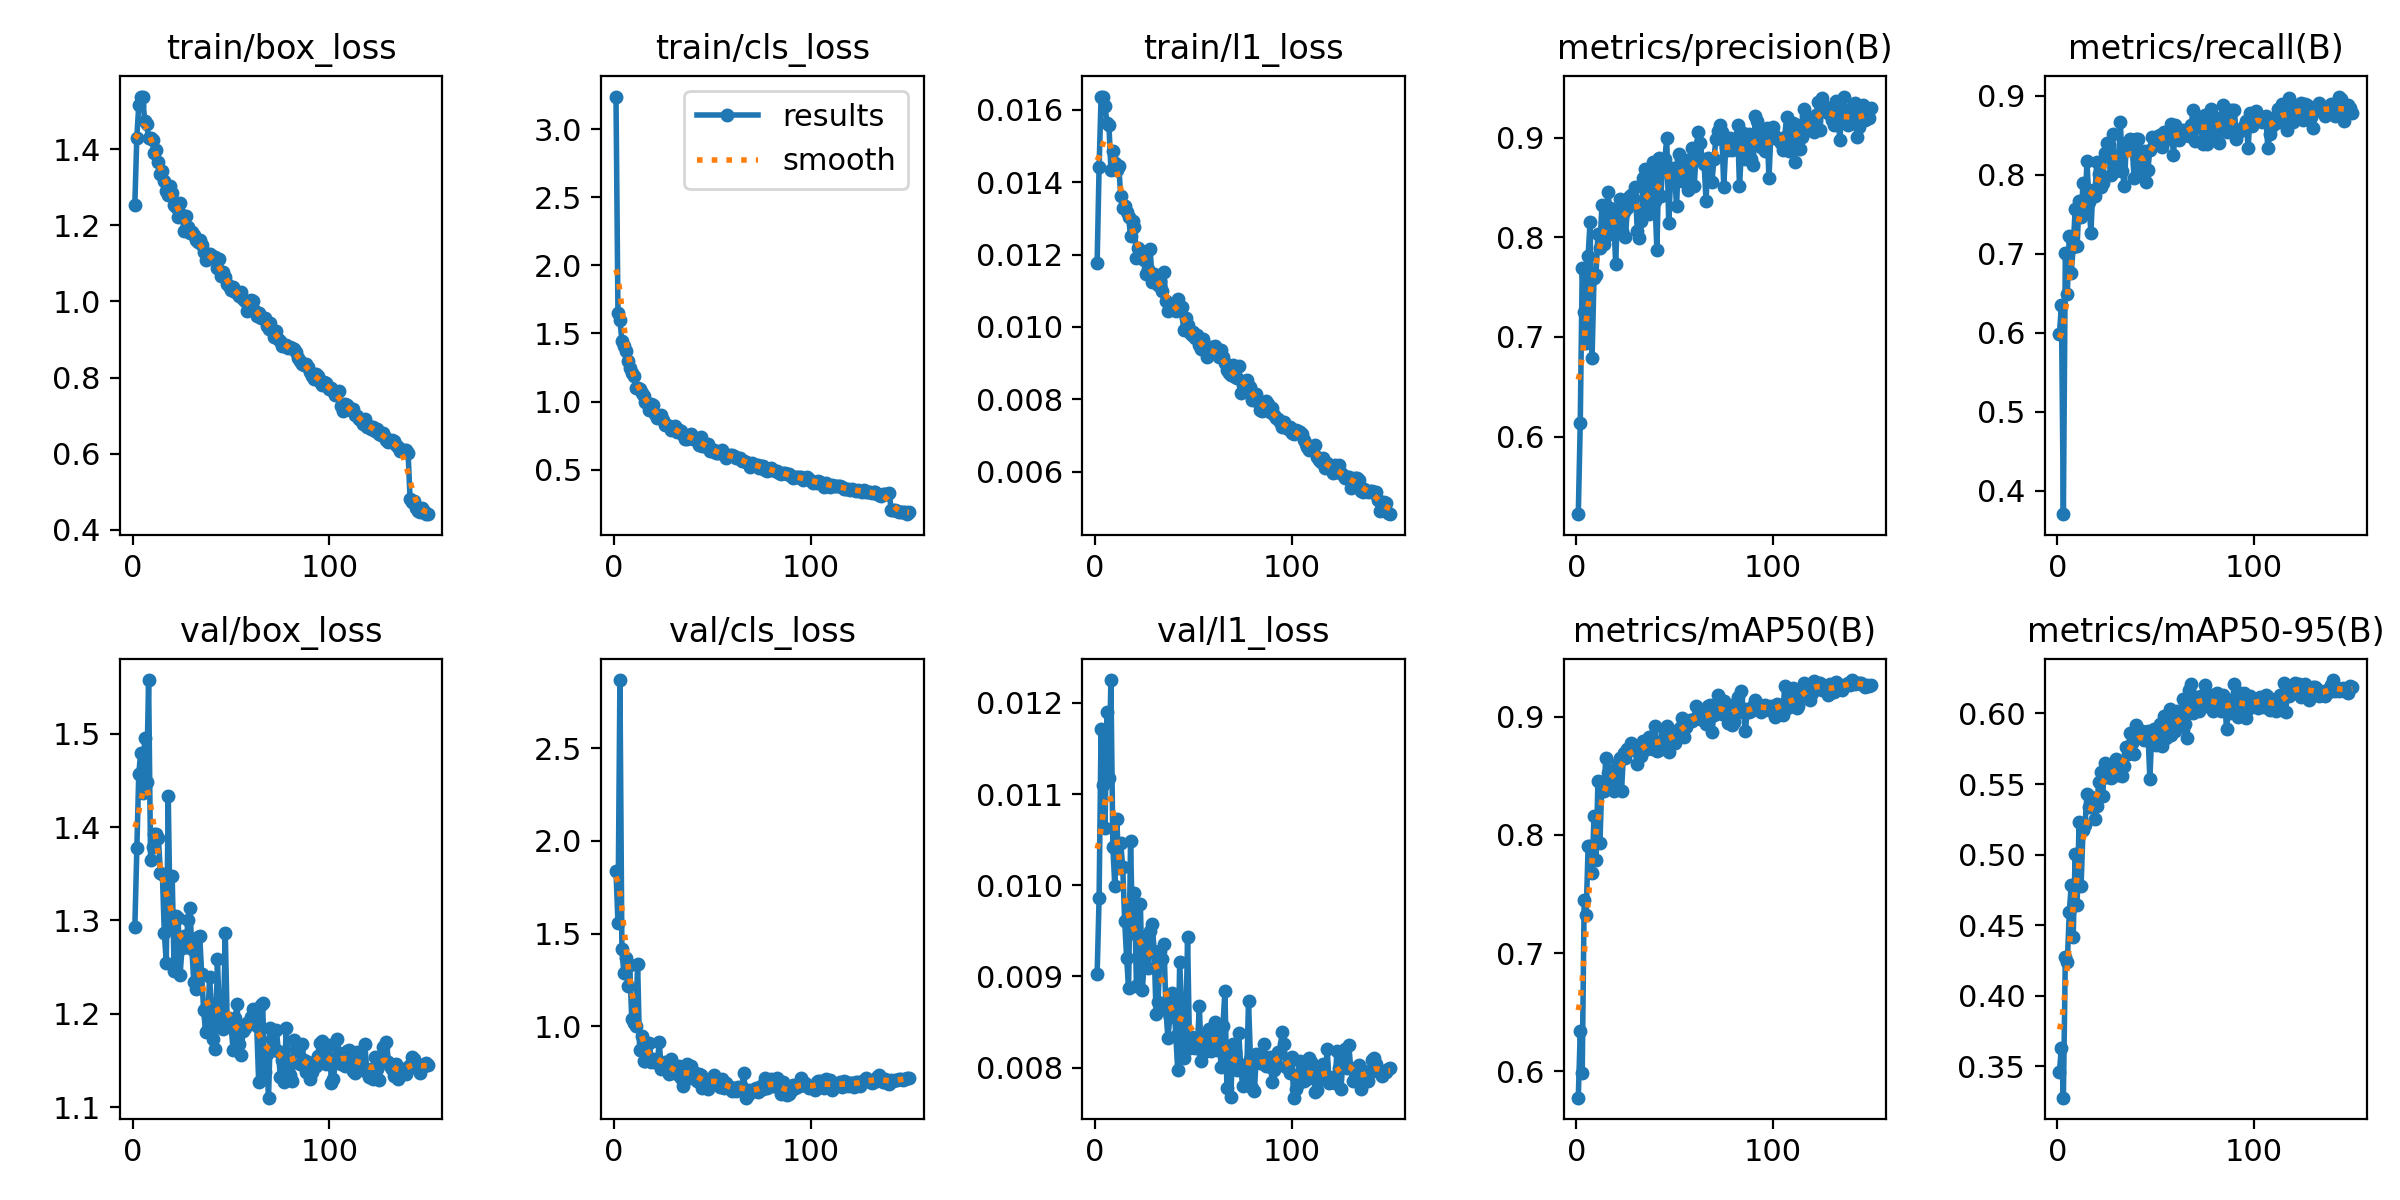

confusion_matrix.png


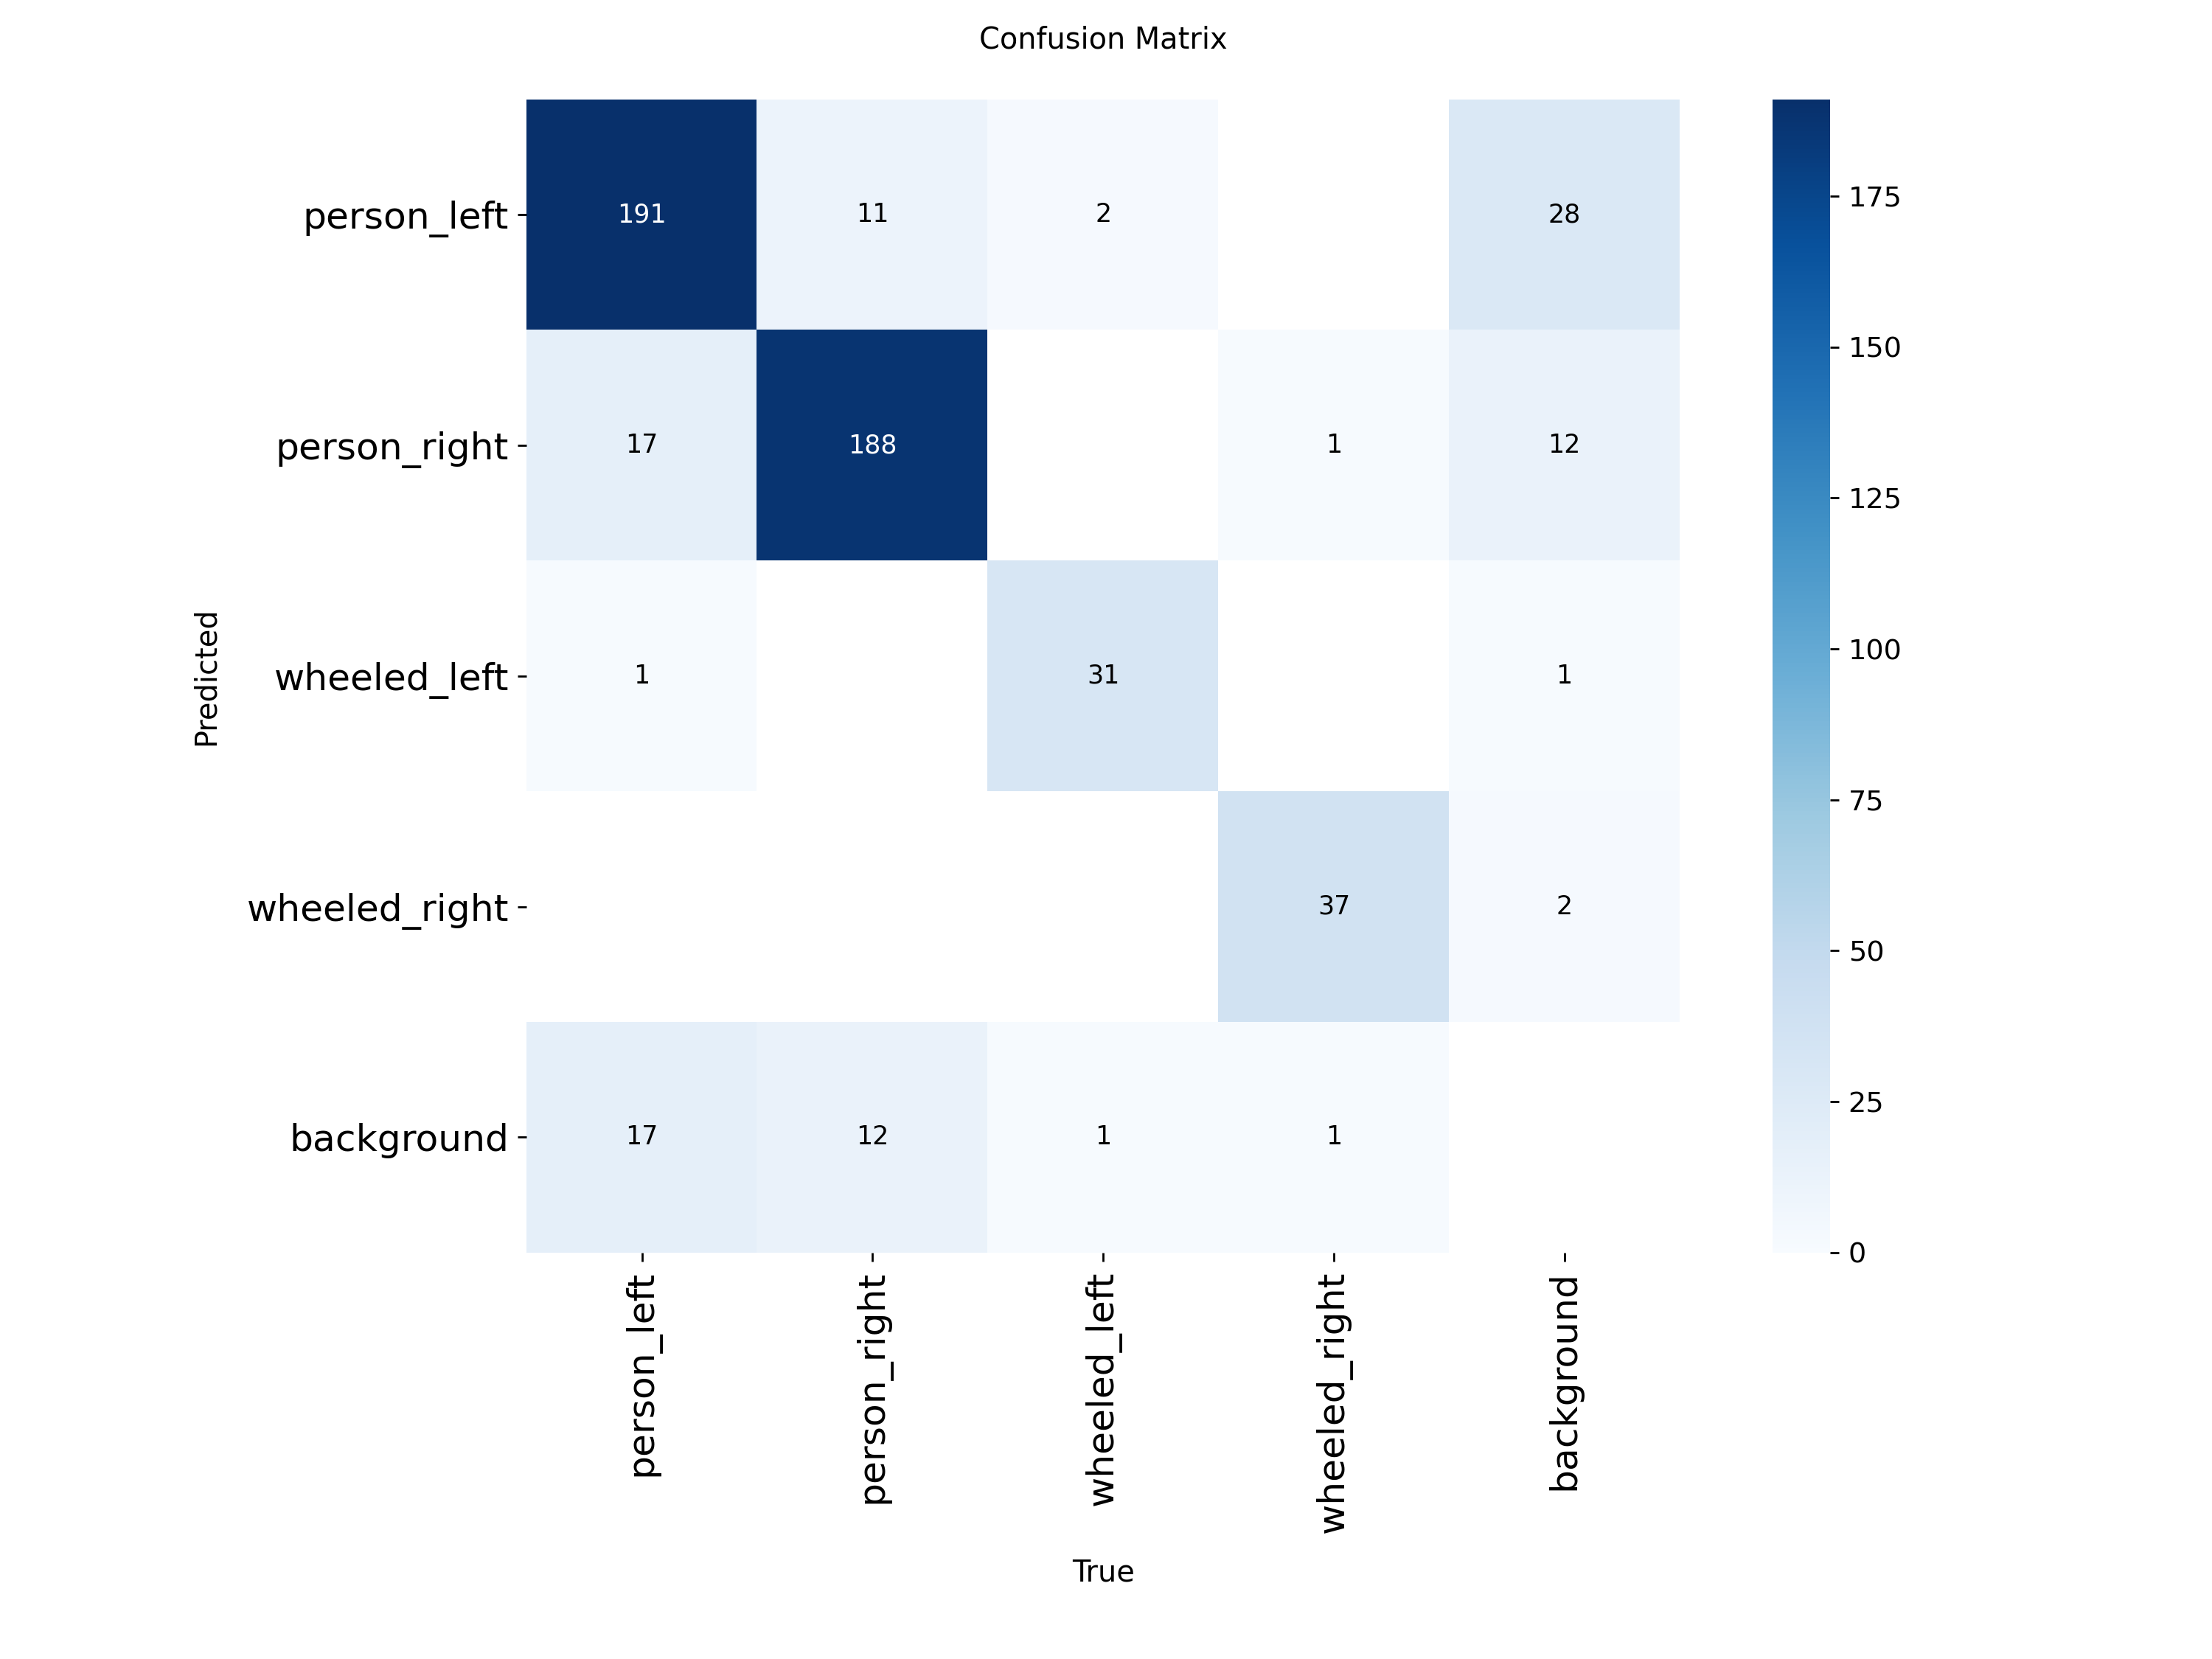

val_batch0_labels.jpg


val_batch0_pred.jpg


In [ ]:
from IPython.display import Image, display

for name in ("results.png", "confusion_matrix.png", "val_batch0_labels.jpg", "val_batch0_pred.jpg"):
    path = os.path.join(RUN_DIR, name)
    if os.path.exists(path):
        print(name)
        display(Image(filename=path, width=800))

## 8. Try a few validation images

In [ ]:
import random
from PIL import Image as PILImage

val_dir = os.path.join(DATA_DIR, "valid", "images")
random.seed(0)
for name in random.sample(sorted(os.listdir(val_dir)), 3):
    result = trained.predict(os.path.join(val_dir, name), conf=0.40, verbose=False)[0]
    counts = {}
    for c in result.boxes.cls.tolist():
        counts[trained.names[int(c)]] = counts.get(trained.names[int(c)], 0) + 1
    print(name.split(".rf.")[0], counts)
    display(PILImage.fromarray(result.plot()[:, :, ::-1]))

## Next

- Weights: `C389_Supernova_Model/runs/final_4cls_ig_v4/weights/best.pt`. Point the app at this file to try it.
- Keep the table from section 6 and `results.png` as evidence for the report.
- Final model: after the labels are fixed and re-exported, train again on a zip that includes test, then evaluate on test **once**.
- Clear outputs before committing this notebook to git (**Edit → Clear all outputs**).